Training on: cuda
Loading data...
Creating sequences...

--- Training Shallow LSTM ---
Epoch 1/10, Loss: 0.030392
Epoch 2/10, Loss: 0.019095
Epoch 3/10, Loss: 0.013863
Epoch 4/10, Loss: 0.011058
Epoch 5/10, Loss: 0.009694
Epoch 6/10, Loss: 0.008778
Epoch 7/10, Loss: 0.008009
Epoch 8/10, Loss: 0.007381
Epoch 9/10, Loss: 0.006847
Epoch 10/10, Loss: 0.006440

--- Training Deep LSTM ---
Epoch 1/10, Loss: 0.032318
Epoch 2/10, Loss: 0.021110
Epoch 3/10, Loss: 0.016425
Epoch 4/10, Loss: 0.014018
Epoch 5/10, Loss: 0.012302
Epoch 6/10, Loss: 0.011101
Epoch 7/10, Loss: 0.010170
Epoch 8/10, Loss: 0.009466
Epoch 9/10, Loss: 0.008974
Epoch 10/10, Loss: 0.008555

Calculating reconstruction errors...
Threshold Model 1: 0.011796
Threshold Model 2: 0.014600

Results for Shallow LSTM:
Precision: 0.9180
Recall:    0.6419
F1-Score:  0.7556
ROC-AUC:   0.9099

Results for Deep LSTM:
Precision: 0.9190
Recall:    0.6505
F1-Score:  0.7618
ROC-AUC:   0.9084


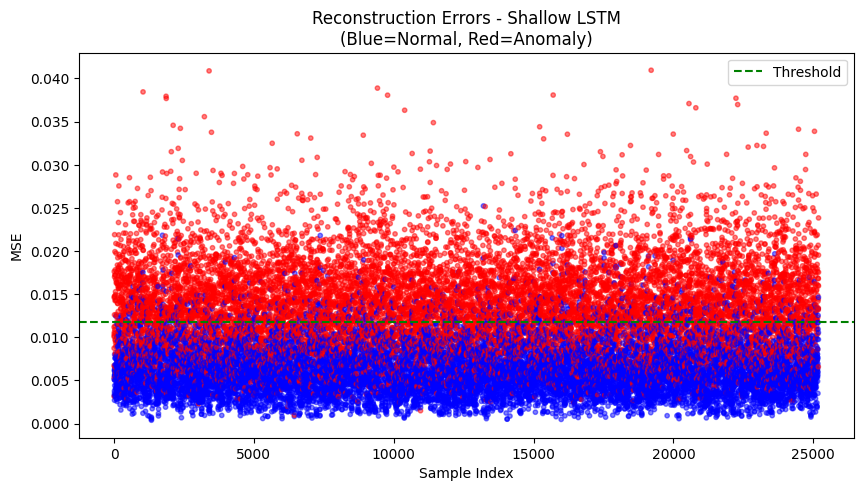

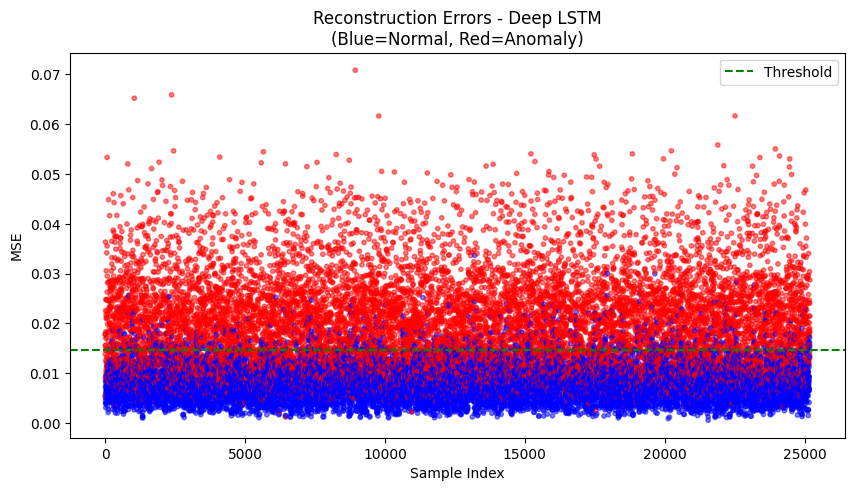


--- Training Baseline (Isolation Forest) ---

Results for Isolation Forest (Baseline):
Precision: 0.9142
Recall:    0.6109
F1-Score:  0.7324
ROC-AUC:   0.9146

=== Assignment 2 Comparison Complete ===


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import IsolationForest

DATA_PATH = "/mnt/c/Users/linne/Skola/Deep-Learning-DV2646/Uppgift 2/Train_data.csv"
TARGET_COL = 'class' 
NORMAL_LABEL = 'normal'

SEQ_LENGTH = 5
BATCH_SIZE = 64
EPOCHS = 10
LEARNING_RATE = 1e-3

# Setup Device as requested
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on: {device}")

# ==========================================
# 1. Data Preprocessing
# ==========================================
def load_and_preprocess_data(filepath):
    print("Loading data...")
    df = pd.read_csv(filepath)
    
    # Handle missing values by dropping rows (or you could fillna)
    df = df.dropna()
    
    if TARGET_COL not in df.columns:
        raise ValueError(f"Target column '{TARGET_COL}' not found. Please update TARGET_COL.")

    # Separate features and labels
    y_raw = df[TARGET_COL]
    X_raw = df.drop(columns=[TARGET_COL])
    
    # One-hot encode categorical features
    X_encoded = pd.get_dummies(X_raw)
    
    # Convert labels to binary: Normal = 0, Anomaly = 1
    y_binary = (y_raw != NORMAL_LABEL).astype(int).values
    
    # Scale features
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X_encoded)
    
    return X_scaled, y_binary, scaler

def create_sequences(X, y, seq_length):
    print("Creating sequences...")
    sequences, labels = [], []
    for i in range(len(X) - seq_length):
        sequences.append(X[i : i + seq_length])
        # Use the label of the last step in the sequence as the sequence label
        labels.append(y[i + seq_length - 1])
    return np.array(sequences), np.array(labels)

# ==========================================
# 2. Model Design
# ==========================================
class ShallowLSTMAutoencoder(nn.Module):
    """Model 1: Shallow Autoencoder (1 layer encoder, 1 layer decoder)"""
    def __init__(self, input_dim, hidden_dim):
        super(ShallowLSTMAutoencoder, self).__init__()
        # Encoder
        self.encoder = nn.LSTM(input_dim, hidden_dim, num_layers=1, batch_first=True)
        # Decoder
        self.decoder = nn.LSTM(hidden_dim, input_dim, num_layers=1, batch_first=True)
        self.output_layer = nn.Linear(input_dim, input_dim)
        
    def forward(self, x):
        _, (hidden, _) = self.encoder(x)
        # hidden is (num_layers, batch_size, hidden_dim) -> (1, B, H)
        # Extract the last layer's hidden state and add sequence dim: (B, 1, H)
        hidden_state = hidden[-1].unsqueeze(1)
        # Repeat it for the sequence length: (B, seq_length, H)
        hidden_rep = hidden_state.repeat(1, x.size(1), 1)
        
        decoded, _ = self.decoder(hidden_rep)
        out = self.output_layer(decoded)
        return out

class DeepLSTMAutoencoder(nn.Module):
    """Model 2: Deep Autoencoder (2 layer encoder, 2 layer decoder)"""
    def __init__(self, input_dim, hidden_dim):
        super(DeepLSTMAutoencoder, self).__init__()
        # Encoder
        self.encoder = nn.LSTM(input_dim, hidden_dim, num_layers=2, batch_first=True, dropout=0.2)
        # Decoder
        self.decoder = nn.LSTM(hidden_dim, input_dim, num_layers=2, batch_first=True, dropout=0.2)
        self.output_layer = nn.Linear(input_dim, input_dim)
        
    def forward(self, x):
        _, (hidden, _) = self.encoder(x)
        # hidden is (num_layers, batch_size, hidden_dim) -> (2, B, H)
        # Extract the top layer's hidden state and add sequence dim: (B, 1, H)
        hidden_top = hidden[-1].unsqueeze(1)
        # Repeat it for the sequence length: (B, seq_length, H)
        hidden_rep = hidden_top.repeat(1, x.size(1), 1)
        
        decoded, _ = self.decoder(hidden_rep)
        out = self.output_layer(decoded)
        return out
# ==========================================
# 3. Training & Evaluation Functions
# ==========================================
def train_model(model, dataloader, epochs, lr, model_name="Model"):
    print(f"\n--- Training {model_name} ---")
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    loss_history = []
    model.train()
    for epoch in range(epochs):
        epoch_loss = 0
        for batch_x in dataloader:
            batch_x = batch_x[0].to(device)
            optimizer.zero_grad()
            output = model(batch_x)
            loss = criterion(output, batch_x)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            
        avg_loss = epoch_loss / len(dataloader)
        loss_history.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.6f}")
        
    return model, loss_history

def get_reconstruction_errors(model, data_tensor):
    model.eval()
    errors = []
    with torch.no_grad():
        for i in range(0, len(data_tensor), BATCH_SIZE):
            batch = data_tensor[i:i+BATCH_SIZE].to(device)
            reconstructed = model(batch)
            # Calculate MSE per sequence
            mse = torch.mean((batch - reconstructed) ** 2, dim=[1, 2])
            errors.extend(mse.cpu().numpy())
    return np.array(errors)

def evaluate_predictions(y_true, y_pred, y_scores, model_name="Model"):
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_scores)
    
    print(f"\nResults for {model_name}:")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    return {"precision": precision, "recall": recall, "f1": f1, "roc_auc": roc_auc}

# ==========================================
# 4. Visualizations
# ==========================================
def plot_errors(errors, labels, threshold, title):
    plt.figure(figsize=(10, 5))
    colors = ['blue' if label == 0 else 'red' for label in labels]
    plt.scatter(range(len(errors)), errors, c=colors, alpha=0.5, s=10)
    plt.axhline(y=threshold, color='green', linestyle='--', label='Threshold')
    plt.title(f'Reconstruction Errors - {title}\n(Blue=Normal, Red=Anomaly)')
    plt.xlabel('Sample Index')
    plt.ylabel('MSE')
    plt.legend()
    plt.show()

# ==========================================
# 5. Main Execution Block
# ==========================================
if __name__ == "__main__":
    # --- Data Prep ---
    X_scaled, y_binary, scaler = load_and_preprocess_data(DATA_PATH)
    X_seq, y_seq = create_sequences(X_scaled, y_binary, SEQ_LENGTH)
    
    # Autoencoders train best on *only* normal data, but test on both.
    # We will split normal vs anomaly for training
    normal_indices = np.where(y_seq == 0)[0]
    anomaly_indices = np.where(y_seq == 1)[0]
    
    # Train using only normal sequences
    X_train_normal = X_seq[normal_indices]
    
    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train_normal)
    X_all_tensor = torch.FloatTensor(X_seq)
    
    train_loader = DataLoader(TensorDataset(X_train_tensor), batch_size=BATCH_SIZE, shuffle=True)
    
    input_dim = X_seq.shape[2]
    hidden_dim = max(16, input_dim // 2)

    # --- Train Model 1 (Shallow) ---
    model1 = ShallowLSTMAutoencoder(input_dim, hidden_dim)
    model1, loss_hist1 = train_model(model1, train_loader, EPOCHS, LEARNING_RATE, "Shallow LSTM")
    
    # --- Train Model 2 (Deep) ---
    model2 = DeepLSTMAutoencoder(input_dim, hidden_dim)
    model2, loss_hist2 = train_model(model2, train_loader, EPOCHS, LEARNING_RATE, "Deep LSTM")

    # --- Evaluate Models ---
    print("\nCalculating reconstruction errors...")
    errors_m1 = get_reconstruction_errors(model1, X_all_tensor)
    errors_m2 = get_reconstruction_errors(model2, X_all_tensor)
    
    # Threshold selection strategy: 95th percentile of errors on normal data
    normal_errors_m1 = get_reconstruction_errors(model1, X_train_tensor)
    normal_errors_m2 = get_reconstruction_errors(model2, X_train_tensor)
    
    threshold_m1 = np.percentile(normal_errors_m1, 95)
    threshold_m2 = np.percentile(normal_errors_m2, 95)
    
    print(f"Threshold Model 1: {threshold_m1:.6f}")
    print(f"Threshold Model 2: {threshold_m2:.6f}")
    
    preds_m1 = (errors_m1 > threshold_m1).astype(int)
    preds_m2 = (errors_m2 > threshold_m2).astype(int)
    
    res_m1 = evaluate_predictions(y_seq, preds_m1, errors_m1, "Shallow LSTM")
    res_m2 = evaluate_predictions(y_seq, preds_m2, errors_m2, "Deep LSTM")
    
    # Visualizations
    plot_errors(errors_m1, y_seq, threshold_m1, "Shallow LSTM")
    plot_errors(errors_m2, y_seq, threshold_m2, "Deep LSTM")

    # --- Baseline Model (Isolation Forest) ---
    print("\n--- Training Baseline (Isolation Forest) ---")
    # IF expects 2D data, so we flatten the sequences: (samples, seq_length * features)
    X_train_if = X_train_normal.reshape(X_train_normal.shape[0], -1)
    X_all_if = X_seq.reshape(X_seq.shape[0], -1)
    
    iso_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
    iso_forest.fit(X_train_if)
    
    # Predictions: 1 for normal, -1 for anomaly. Convert to 0 normal, 1 anomaly.
    preds_if_raw = iso_forest.predict(X_all_if)
    preds_if = np.where(preds_if_raw == 1, 0, 1)
    
    # Anomaly score (decision function: lower is more anomalous. We invert it for ROC-AUC)
    scores_if = -iso_forest.decision_function(X_all_if)
    
    res_if = evaluate_predictions(y_seq, preds_if, scores_if, "Isolation Forest (Baseline)")